# Chapter 3 — A private quarrel, or a pile-on?

When one subreddit publicly attacks another, who gets involved? Chapters 1 and 2 look at the pair A–B. Here we look at everything **around** them: the other communities.

> **Is an attack a private quarrel between two communities, or does the attacker's circle pile on?**

**Vocabulary.** *Attack* = the first negative link ever received by a subreddit B, from 2015 on. **A** is the attacker, **B** the target, **C** any third community that links to B. A *control* B′ is a subreddit that looked like B before the attack but was not attacked at that date: it tells us what would have happened without the attack.

## Three acts

**1 - The spotlight**  
Do other communities start linking to B after the attack ? 
-> Links to B from third communities, before vs after

**2 - The crowd**  
Who arrives? Are A's friends over-represented ? 
-> Share of linkers already connected to A, before vs after

**3 - The tone**  
Do tiers players' interventions tend to be more negative after an attack ?
-> Ratio of negative links received by B from C (a subreddit that is not A or B)

## Hypotheses

| Act | We expect... | We would change our mind if... |
|---|---|---|
| 1 | More links to B than to B′ after the attack, and a more negative share | The B / B′ ratio is close to 1 (interval includes 1); the negative share is the same as for B′ |
| 2 | A higher share of linkers connected to A after the attack, compared with before and with B′ | The share is the same before and after, and the same for B′ |
| 3 | Linkers connected to A are more hostile than their usual habits predict (contagion) | Observed ≈ expected: they are simply habitual attackers (selection) |

## 0. Setup and data

We load the two files (links found in post bodies and in post titles), stack them, drop self-links and sort by time. Sorting matters: "the first negative link" and the fast date slicing used later both rely on it.

In [95]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
BLUE, RED, GREY = "#1E67B5", "#D02F2F", "#7F7F7F"   # same colors as chapter 2
DAY = pd.Timedelta(days=1)                           # handy unit for time arithmetic

In [96]:
DATA_DIR = Path("data/raw")   # folder containing the two SNAP .tsv files
COLUMNS = ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP", "LINK_SENTIMENT"]

# Load body and title links and stack them (same columns, so concat simply appends rows).
parts = []
for location in ["body", "title"]:
    part = pd.read_csv(DATA_DIR / f"soc-redditHyperlinks-{location}.tsv", sep="\t", usecols=COLUMNS)
    part["LOCATION"] = location                     # remember where the link was found
    parts.append(part)
links = pd.concat(parts, ignore_index=True)

links["time"] = pd.to_datetime(links.pop("TIMESTAMP"))              # pop = remove the column, then convert it
links = links[links.SOURCE_SUBREDDIT != links.TARGET_SUBREDDIT]     # drop self-links
links = links.sort_values(["time", "POST_ID", "LOCATION"]).reset_index(drop=True)   # ties broken deterministically

assert links[COLUMNS[:3] + ["LINK_SENTIMENT"]].notna().all().all()
assert set(links.LINK_SENTIMENT) == {-1, 1}
print(f"{len(links):,} links | {links.LINK_SENTIMENT.eq(-1).mean():.2%} negative")
print(links.time.min(), "->", links.time.max())

858,488 links | 9.58% negative
2013-12-31 16:20:20 -> 2017-04-30 16:58:21


## 1. Events

**Definition.** An event is the *first negative link ever received* by a subreddit B (from A at time `t0`). We keep it only if:
- it happens on 1 January 2015 or later (2014 is used only to check that B had never been attacked before);
- we observe the 30 days that follow (the data stops at the end of April 2017).

We want it to be the first attack to be abble to study the 'spotlight effect' that a first attack has. We assume that a group that have already benefitted from it may be less sensitive to another one.

There is one event per B.

In [97]:
# Sort then keep the first row per group = the first event of each entity.
negatives = links[links.LINK_SENTIMENT == -1]
first_neg_time = negatives.groupby("TARGET_SUBREDDIT").time.min()

events = negatives.drop_duplicates("TARGET_SUBREDDIT", keep="first")   # links is sorted: keeps the earliest
events = events.rename(columns={"SOURCE_SUBREDDIT": "A", "TARGET_SUBREDDIT": "B", "time": "t0"})
events = events[["A", "B", "t0"]]
n_attacked_ever = len(events)

events = events[events.t0 >= "2015-01-01"]
n_from_2015 = len(events)

events = events[events.t0 + 31 * DAY <= links.time.max()].reset_index(drop=True)   # full 30 days of follow-up
events["event_id"] = events.index
print(f"{n_attacked_ever:,} attacked subreddits -> {n_from_2015:,} first attacks from 2015 -> {len(events):,} with 30 days of follow-up")

6,635 attacked subreddits -> 4,197 first attacks from 2015 -> 4,000 with 30 days of follow-up


### 1.1 The table of incoming links (`long`)

Everything else is computed from one table with **one row per link received by B**, from a third community C (never from A), between 180 days before and 365 days after the attack.

| column | meaning |
|---|---|
| `event_id` | which attack (therefore which B) |
| `C` | the community that posted the link |
| `rel_day` | days since the attack (negative = before, positive = after) |
| `is_neg` | is the link negative? |

Once we have it, counting links in a window is just a `groupby`.

In [98]:
def incoming_links(events, links, lo=-180, hi=365):
    "Make a table of the incomming link to the attacked subredits in the defined window and from third parties"
    m = events.merge(links, left_on="B", right_on="TARGET_SUBREDDIT", how="left")
    m["rel_day"] = (m.time - m.t0) // DAY
    m["C"] = m.SOURCE_SUBREDDIT
    m["is_neg"] = m.LINK_SENTIMENT == -1

    in_window = (m.rel_day >= lo) & (m.rel_day <= hi)
    from_third = m.C != m.A
    m = m[in_window & from_third]

    return m[["event_id", "C", "rel_day", "is_neg"]].reset_index(drop=True)

long = incoming_links(events, links)
print(f"{len(long):,} incoming links around the attacks (-180 days to + 1 year)")
long.head()

70,943 incoming links around the attacks (-180 days to + 1 year)


,event_id,C,rel_day,is_neg
0,1,gurbani,-171,False
1,1,punjabi,-148,False
2,1,gurbani,-128,False
3,1,gurbani,43,False
4,1,gurbani,43,False


### 1.2 Time windows and counts

Windows are written `[lo, hi)` in days around the attack (hi excluded).
- `elig` = [-180, -90): used **only** to select active subreddits.
- `pre30` = [-30, 0) and `post30` = [1, 31): the windows we compare.  
_We exclude day0 (attack) from the post window because a attacking link could be triggered by an increased visibility of the sub-reddit just before, which should not be considered as a consequence of the attack_.

We select an earlier window than the one we measure to avoids a fake decline: a subreddit picked because it was unusually active (stocchastic) just before the attack would tend to fall back by itself.

In [99]:
MIN_LINKS = 4   # eligibility: at least 4 incoming links in the `elig` window

WINDOWS = {"elig": (-180, -90), "pre90": (-90, 0), "pre30": (-30, 0), "post30": (1, 31)}

def add_counts(table, long, windows=WINDOWS):
    """For each window, add the number of incoming links (<name>_n) and of negative ones (<name>_neg)."""
    table = table.copy()

    for name, (lo, hi) in windows.items():
        w = long[(long.rel_day >= lo) & (long.rel_day < hi)]
        groupped = w.groupby("event_id")

        n_tot = groupped["C"].size()
        n_neg = groupped["is_neg"].sum()

        counts = pd.DataFrame({f"{name}_n": n_tot, f"{name}_neg": n_neg})

        table = table.join(counts, on="event_id")
    
    count_cols = [c for c in table if c.endswith(("_n", "_neg"))]
    table[count_cols] = table[count_cols].fillna(0).astype(int)    # no link at all means 0, not NaN
    return table

# Correct the merge error with column overlapping :
count_cols = [f"{name}_{suffix}" for name in WINDOWS for suffix in ("n", "neg")]

events = add_counts(events.drop(columns=count_cols, errors="ignore"), long)
events["eligible"] = events.elig_n >= MIN_LINKS
print(f"{events.eligible.sum()} eligible events out of {len(events):,}")

455 eligible events out of 4,000


### 1.3 How many attacks can we analyse?

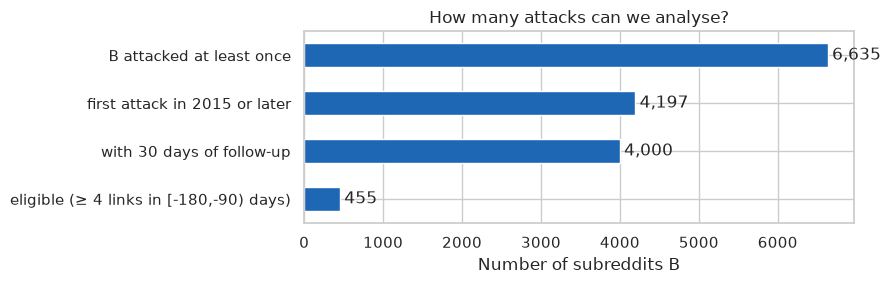

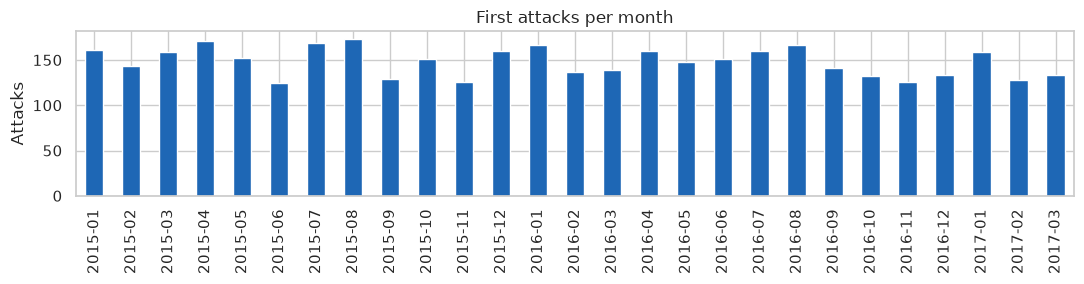

In [100]:
# Visual 1: from all attacked subreddits down to the eligible ones.
funnel = pd.Series({
    "B attacked at least once": n_attacked_ever,
    "first attack in 2015 or later": n_from_2015,
    "with 30 days of follow-up": len(events),
    f"eligible (≥ {MIN_LINKS} links in [-180,-90) days)": events.eligible.sum(),
})
ax = funnel[::-1].plot.barh(color=BLUE, figsize=(9, 3))     # [::-1] puts the first step on top
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
ax.set(title="How many attacks can we analyse?", xlabel="Number of subreddits B")
plt.tight_layout(); plt.show()

# Visual 2: first attacks per month, to spot shocks.
monthly = events.t0.dt.to_period("M").value_counts().sort_index()
ax = monthly.plot(kind="bar", color=BLUE, figsize=(11, 3))
ax.set(title="First attacks per month", xlabel="", ylabel="Attacks")
plt.tight_layout(); plt.show()

Most attacked subreddits receive very few links, so the analysis rests on the eligible ones. Eventually, our sample is composed of 337 attacked datasets.  
Also, the number of first attacks seems to be quite stable over time and we cannot see any disruptive burst.

## 2. Controls (what would have happened without the attack?)

If B receives X % more links after the attack, we cannot tell whether the attack is the cause as it could also be a site-wide event or a community already growing. So for each eligible B we look for a control B′: a subreddit that, at the same date `t0`,
- had the same number of incoming links in `elig` and in `pre90`,
- had never received a negative link before `t0` (so that it is comparable to B).

The best candidate is the one with the smallest distance, measured on a log scale (`log1p`, so that 100 vs 110 links is "close" while 5 vs 15 is not). 
A subreddit can serve as control for two events at different dates.

In [101]:
max_d = 0.5                           # maximum distance between B and its control (log units)
link_times = links["time"].to_numpy()   # sorted array: lets us slice by date with a binary search

def find_control(event):
    """Return (best control subreddit, distance) for one event, or None."""
    start = np.searchsorted(link_times, (event.t0 - 180 * DAY).to_datetime64())
    stop = np.searchsorted(link_times, event.t0.to_datetime64())
    w = links.iloc[start:stop]
    w = w[w.SOURCE_SUBREDDIT != ev.A]                                # same rule as for B: ignore links from A

    # Incoming links of every subreddit in the two windows (elig = more than 90 days before t0, pre90 = the rest).
    period = np.where((ev.t0 - w.time) / DAY > 90, "elig", "pre90")
    counts = (w.assign(period=period).groupby(["TARGET_SUBREDDIT", "period"]).size()
                .unstack(fill_value=0).reindex(columns=["elig", "pre90"], fill_value=0))

    cand = counts[counts.elig >= MIN_LINKS].drop(index=[ev.B, ev.A], errors="ignore")   # active enough, not B or A
    first_neg = first_neg_time.reindex(cand.index)
    cand = cand[(first_neg.isna() | (first_neg >= ev.t0 + DAY)).to_numpy()]            # not attacked yet at t0
    if cand.empty:
        return None

    dist = ((np.log1p(cand.elig) - np.log1p(ev.elig_n)).abs()
            + (np.log1p(cand.pre90) - np.log1p(ev.pre90_n)).abs())
    return dist.idxmin(), dist.min()

rows = []
for ev in events[events.eligible].itertuples():
    res = find_control(ev)
    if res is not None:
        rows.append({"event_id": ev.event_id, "control": res[0], "dist": res[1]})
controls = pd.DataFrame(rows)
controls = controls[controls.dist <= max_d]
print(f"{len(controls)} / {events.eligible.sum()} events matched | {controls.control.nunique()} distinct controls")

449 / 455 events matched | 334 distinct controls


**Give the controls the same columns as the events**

The control B′ plays the role of B: same event, same `t0`, **same A** (so that later we can ask whether the communities linking to B′ are also tied to A, as a placebo).

In [102]:
# One row per matched event, with B' in column B.
controls = controls.merge(events[["event_id", "A", "t0"]], on="event_id").rename(columns={"control": "B"})

# Controls attacked within 30 days of t0 are kept (dropping them would bias the negative share down by construction).
controls["attacked_post30"] = first_neg_time.reindex(controls.B).to_numpy() < (controls.t0 + 31 * DAY).to_numpy()
print(f"{controls.attacked_post30.mean():.1%} of controls are attacked within 30 days")

ctrl_long = incoming_links(controls, links)      # same function, same table format as for the events
controls = add_counts(controls, ctrl_long)
assert (controls.elig_n >= MIN_LINKS).all()

# Aligned tables: same events, same order, for attacked B (ev_m) and control B' (ct_m).
ids = controls.event_id.to_numpy()
ev_m = events.set_index("event_id").loc[ids]
ct_m = controls.set_index("event_id").loc[ids]

3.1% of controls are attacked within 30 days


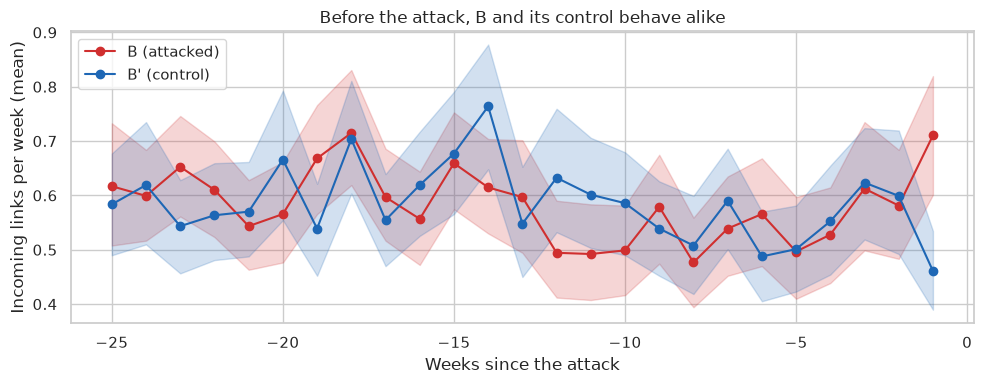

In [103]:
def weekly_table(long, ids, weeks):
    """Rows = events, columns = weeks around the attack, values = number of incoming links."""
    w = long[long.event_id.isin(ids)].copy()
    w["week"] = np.floor(w.rel_day / 7).astype(int)                  # week -1 = days [-7, 0), week 0 = days [0, 7)
    tab = w.groupby(["event_id", "week"]).size().unstack(fill_value=0)
    return tab.reindex(index=ids, columns=list(weeks), fill_value=0)  # weeks with no link become 0

def bootstrap_mean(tab, n_boot=1000, seed=0):
    """Mean per week with a 95% interval, resampling EVENTS (rows) with replacement."""
    rng = np.random.default_rng(seed)
    X = tab.to_numpy()
    means = np.array([X[rng.integers(0, len(X), len(X))].mean(axis=0) for _ in range(n_boot)])
    low, high = np.percentile(means, [2.5, 97.5], axis=0)
    return X.mean(axis=0), low, high

def plot_weekly(ids, weeks, title, attack_line=False):
    fig, ax = plt.subplots(figsize=(10, 4))
    for label, lg, color in [("B (attacked)", long, RED), ("B' (control)", ctrl_long, BLUE)]:
        mean, low, high = bootstrap_mean(weekly_table(lg, ids, weeks))
        ax.plot(list(weeks), mean, color=color, marker="o", label=label)
        ax.fill_between(list(weeks), low, high, color=color, alpha=0.2)
    if attack_line:
        ax.axvline(-0.5, ls="--", color="k")        # the attack happens at the start of week 0
    ax.set(title=title, xlabel="Weeks since the attack", ylabel="Incoming links per week (mean)")
    ax.legend(); plt.tight_layout(); plt.show()

plot_weekly(ids, range(-25, 0), "Before the attack, B and its control behave alike")

One can appreciate that before the attack, B and B′ show the same activity and the same trend, so a difference after the attack can be attributed to the attack with more confidence.  
One can already grasp the effect of the attack by looking at the beginning of week 0 where the two curves already dissociate (due to the atacks in beginning of the week)

## 3 - Act 1 : The spotlight

**Question.** After the attack, do other communities link to B more than they link to a similar subreddit that was not attacked? And are those links hostile?

### 3.1 The curve around the attack

We will look at the 13 weeks before and after the attack. So that the latter mean values for links received is not affected, we select for events with at least a 91 days (13 week) follow up.  
Otherwise, the missing data at the end could bring the mean values down.

429 matched events with 91 days of follow-up


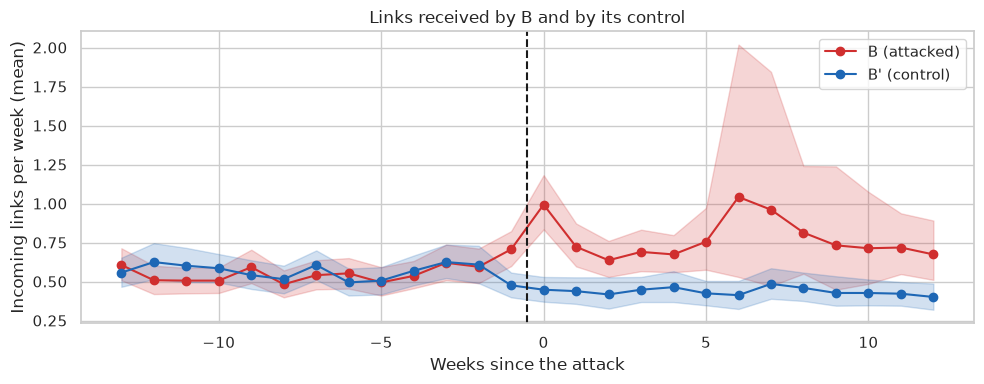

In [104]:
full_91 = ev_m.t0 + 91 * DAY <= links.time.max()
curve_ids = ids[full_91.to_numpy()]
print(f"{len(curve_ids)} matched events with 91 days of follow-up")

plot_weekly(curve_ids, range(-13, 13), "Links received by B and by its control", attack_line=True)

This peak around 6-7 weeks is unexpected. As the number of links was not normalized, it may be driven by a single big sub-reddit with an abnormal event.  
Let's investigate it by plotting the same curve, but normalized and by looking at which subreddit received the most links in this period.


In [108]:
# The events that contribute most to the links received in weeks 5 to 7.
tab = weekly_table(long, curve_ids, range(-13, 13))
top = tab[[5, 6, 7]].sum(axis=1).sort_values(ascending=False).head(5)
display(events.set_index("event_id").loc[top.index, ["A", "B", "t0"]].assign(links_weeks_5_to_7=top))
print(f"Pokemongo = {top.sum() / tab[[5, 6, 7]].to_numpy().sum():.0%} of all links in weeks 5-7")

,A,B,t0,links_weeks_5_to_7
event_id,,,,
2545,pokemongoblue,pokemongo,2016-05-26 18:24:11,386
3099,shitstatistssay,garyjohnson,2016-09-12 00:35:33,28
1965,hoverjunkers,vive,2016-01-28 14:55:01,20
1861,jezopolis,whowouldwinverse,2016-01-09 13:59:14,15
928,bipolar,mneumonese,2015-07-05 00:48:16,14


Pokemongo = 39% of all links in weeks 5-7


Indeed, this subreddit called pokemongo received 44% of all the links received in the 5-7 days interval after the attack.

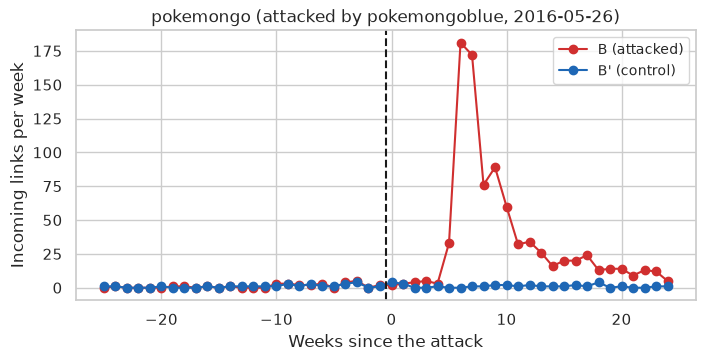

In [109]:
plot_pair(2545, range(-25, 25), title="pokemongo (attacked by pokemongoblue, 2016-05-26)", attack_line=True)

For the most curious of you here is an insight into why this may be the case :   
>On May 25, 2016, Niantic expanded the Pokémon GO field-test beta to the United States, sending invites to people who had signed up earlier that month. This lead to many screenshots and content sharing

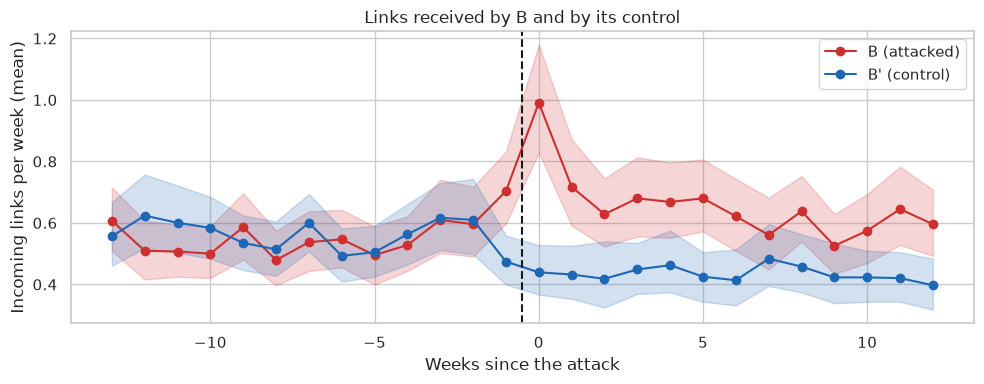

In [111]:
# poping pokemongo out of the tab to erase its outlier effect
events = events[events.event_id != 2545]
# pop it from ids
curve_ids = curve_ids[curve_ids != 2545]
plot_weekly(curve_ids, range(-13, 13), "Links received by B and by its control", attack_line=True)

This seems to confirm that this subreddit was driving this effect on its own.

### 3.2 How much more? A ratio of ratios

For each group (B and B′) we compute `links in the 30 days after / links in the 30 days before`, then divide the two: the result is "B's attention grew **x times more** than the control's". The interval comes from resampling events with replacement (bootstrap). Day 0 is left out.


There is no simple closed-form formula for the standard error of the ratio of a ratio.  
The bootstrap solves this empirically: resample the events, recompute the statistic each time, and read the spread of the result directly.

In [ ]:
def boot_ratios(ev, ct, n_boot=1000, seed=41):

    a = [ev.post30_n, ev.pre30_n, ct.post30_n, ct.pre30_n]
    a = [x.to_numpy(float) for x in a]
    n = len(a[0])

    pick = np.random.default_rng(seed).integers(0, n, (n_boot, n))

    def stats(post_b, pre_b, post_c, pre_c):
        rb, rc = post_b / pre_b, post_c / pre_c
        return np.array([rb, rc, rb / rc])

    point = stats(*[x.sum() for x in a])
    boot = stats(*[x[pick].sum(axis=1) for x in a])
    low, high = np.percentile(boot, [2.5, 97.5], axis=1)


    return pd.DataFrame({"estimate": point, "low": low, "high": high},
                        index=["B: after / before", "B': after / before", "B / B' (ratio of ratios)"])

ratios = boot_ratios(ev_m, ct_m)
display(ratios.round(2))

,estimate,low,high
B: after / before,1.21,1.07,1.36
B': after / before,0.78,0.68,0.88
B / B' (ratio of ratios),1.56,1.34,1.83


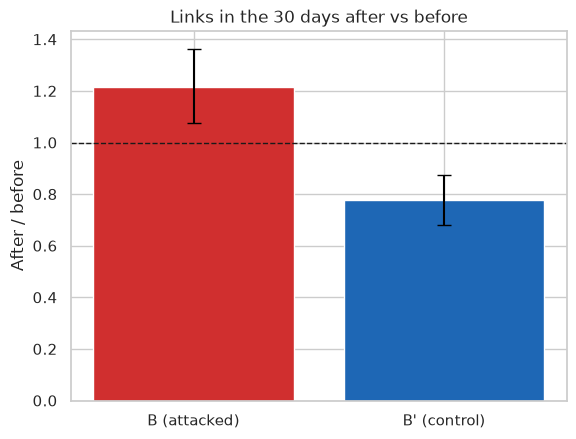

In [ ]:
# Left: after / before, for B and for its control (1 = no change)
for i, (name, color) in enumerate([("B: after / before", RED), ("B': after / before", BLUE)]):
    r = ratios.loc[name]
    plt.bar(i, r.estimate, color=color)
    plt.errorbar(i, r.estimate, yerr=[[r.estimate - r.low], [r.high - r.estimate]],
                 fmt="none", color="black", capsize=5)

ax = plt.gca()
ax.axhline(1, color="k", lw=1, ls="--")
ax.set_xticks([0, 1], ["B (attacked)", "B' (control)"])
ax.set(title="Links in the 30 days after vs before", ylabel="After / before")
plt.show()

### 3.3 Is the attention hostile?

We compare the share of negative links after the attack, B against B′.

,share,low,high
B (attacked),0.038,0.025,0.052
B' (control),0.019,0.009,0.030


,difference,low,high,p_value
B minus B',0.019,0.001,0.036,0.038


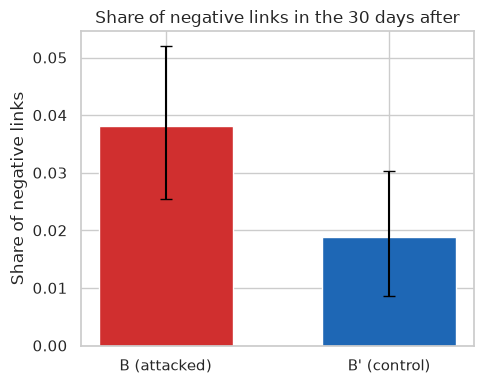

In [ ]:
def share_ci(table, num, den, n_boot=1000, seed=0):
    """Ratio sum(num) / sum(den) with a 95% interval, resampling EVENTS with replacement.
    `table` needs an `event_id` column; any number of rows per event is fine."""
    per_event = table.groupby("event_id")[[num, den]].sum()
    a, b = per_event[num].to_numpy(float), per_event[den].to_numpy(float)
    pick = np.random.default_rng(seed).integers(0, len(per_event), (n_boot, len(per_event)))
    boot = a[pick].sum(axis=1) / b[pick].sum(axis=1)
    return a.sum() / b.sum(), *np.percentile(boot, [2.5, 97.5])

def bar_with_ci(ax, positions, d, color, label, width=0.35):
    ax.bar(positions, d.share, width, color=color, label=label)
    ax.errorbar(positions, d.share, yerr=[d.share - d.low, d.high - d.share], fmt="none", color="black", capsize=4)

neg = pd.DataFrame([share_ci(t.reset_index(), "post30_neg", "post30_n") for t in (ev_m, ct_m)],
                   columns=["share", "low", "high"], index=["B (attacked)", "B' (control)"])
display(neg.round(3))

def boot_share_diff(ev, ct, num, den, n_boot=1000, seed=0):
    """Difference between the negative share of B and of its control (B minus B'), with a 95% interval and
    a p-value. Events are resampled together (same indices for B and B'), since each B is paired with its B'."""
    a_num, a_den = ev[num].to_numpy(float), ev[den].to_numpy(float)
    c_num, c_den = ct[num].to_numpy(float), ct[den].to_numpy(float)
    diff = lambda i: a_num[i].sum() / a_den[i].sum() - c_num[i].sum() / c_den[i].sum()
    rng = np.random.default_rng(seed)
    n = len(ev)
    draws = np.array([diff(rng.integers(0, n, n)) for _ in range(n_boot)])
    low, high = np.percentile(draws, [2.5, 97.5])
    return pd.Series({"difference": diff(np.arange(n)), "low": low, "high": high, "p_value": boot_p(draws, null=0.0)})

display(boot_share_diff(ev_m, ct_m, "post30_neg", "post30_n").round(3).to_frame("B minus B'").T)


fig, ax = plt.subplots(figsize=(5, 4))
for i, (name, color) in enumerate([("B (attacked)", RED), ("B' (control)", BLUE)]):
    bar_with_ci(ax, [i], neg.loc[[name]], color, name, width=0.6)
ax.set_xticks([0, 1], ["B (attacked)", "B' (control)"])
ax.set(title="Share of negative links in the 30 days after", ylabel="Share of negative links")
plt.tight_layout(); plt.show()

In the 30 days after an attack, 3.8 % of the links received by B are negative, against 1.9 % for the matched controls (difference: 1.9 points, 95 % interval [0.1, 3.6], p = 0.038).   
The attention that follows an attack is therefore about twice as likely to be hostile as the attention a comparable subreddit receives, but the evidence is borderline (the interval barely excludes zero) and the absolute level stays low: negative links remain a small minority, far below the 9.6 % average of the whole dataset. Most of the new attention is not hostile.

## 4. Acts 2 and 3 - Exploring signed temporal triangles

Beyond measuring changes in attention toward a targeted subreddit, we investigate whether the pre-existing relationships between communities are associated with subsequent negative interactions.

More specifically, we test the following hypothesis:

**Are communities positively connected to an attacker A more likely to link negatively to the target B after A publishes a negative link toward B?**

This analysis aims to explore whether negative interactions involve communities that were already connected to the attacker. It does not establish that the initial negative link caused subsequent interactions.

### 4.1 - Detecting signed temporal triangles

For each negative event A → B at time t0, we investigate whether third-party communities C were positively connected to A before the event and subsequently linked negatively to B.

We use two event-centered observation windows:

- **90 days before t0:** identify positive hyperlinks between A and C, regardless of direction (A → C or C → A).
- **30 days after t0:** observe hyperlinks from C to B and their sentiment.

A triangle matching our hypothesis consists of:

1. At least one positive hyperlink between A and C during the 90 days before t0.
2. A negative hyperlink A → B at t0.
3. At least one negative hyperlink C → B within the following 30 days.

We additionally record whether C had already linked to B during the preceding 90 days. This helps distinguish previously observed C–B interactions from interactions not observed in the recent history.

For this preliminary analysis, a single positive hyperlink is sufficient to classify A and C as positively connected. This does not necessarily imply that the two communities are allies.

The 90-day and 30-day windows are methodological choices that can be tested with alternative durations in the final analysis.

In [ ]:
# One table of links per target and one per source: a fast way to look up all the links of a given subreddit.
links_by_target = {
    target: group 
    for target, group in links.groupby("TARGET_SUBREDDIT")
}
links_by_source = {
    source: group 
    for source, group in links.groupby("SOURCE_SUBREDDIT")
}

def find_triangles_fast(A, B, t0, window=30, lookback=90):

    start = t0 - pd.Timedelta(days=lookback)

    # 1. Find C → B links after the attack
    target_links = links_by_target.get(B)

    if target_links is None:
        return None

    after = target_links[
        (target_links["time"] > t0) &
        (target_links["time"] <= t0 + pd.Timedelta(days=window)) &
        (target_links["SOURCE_SUBREDDIT"] != A) &
        (target_links["SOURCE_SUBREDDIT"] != B)
    ].copy()

    if after.empty:
        return None

    # 2. Find positive connections A ↔ C before the attack
    outgoing = links_by_source.get(A)
    incoming = links_by_target.get(A)

    positive_neighbors = set()

    if outgoing is not None:
        positive_neighbors.update(
            outgoing.loc[
                (outgoing["time"] >= start) &
                (outgoing["time"] < t0) &
                (outgoing["LINK_SENTIMENT"] == 1),
                "TARGET_SUBREDDIT"
            ]
        )

    if incoming is not None:
        positive_neighbors.update(
            incoming.loc[
                (incoming["time"] >= start) &
                (incoming["time"] < t0) &
                (incoming["LINK_SENTIMENT"] == 1),
                "SOURCE_SUBREDDIT"
            ]
        )

    # 3. Find previous connections C → B
    previous_CB = target_links[
        (target_links["time"] >= start) &
        (target_links["time"] < t0)
    ]

    previous_sources = set(
        previous_CB["SOURCE_SUBREDDIT"]
    )

    # 4. Add information to the dataframe
    after["A"] = A
    after["B"] = B
    after["C"] = after["SOURCE_SUBREDDIT"]
    after["t0"] = t0

    after["positive_AC"] = (
        after["C"].isin(positive_neighbors)
    )

    after["previous_CB"] = (
        after["C"].isin(previous_sources)
    )

    after["negative_CB"] = (
        after["LINK_SENTIMENT"] == -1
    )

    return after

In [ ]:
def run_triangles(table):
    # table: one row per event, with columns A, B and t0 (events or controls)
    all_results = []

    for event in table.itertuples(index=False):

        result = find_triangles_fast(
            A=event.A,
            B=event.B,
            t0=event.t0,
            window=30,
            lookback=90
        )

        if result is not None:
            all_results.append(result)

    if all_results:
        return pd.concat(all_results, ignore_index=True)
    return pd.DataFrame()

all_third_party_links = run_triangles(events)      # attacked B
ctrl_third_party_links = run_triangles(controls)   # control B'

# Add our event_id, so that these tables connect with `events`, `controls` and the bootstrap helpers.
n_rows = len(all_third_party_links), len(ctrl_third_party_links)
all_third_party_links = all_third_party_links.merge(events[["A", "B", "t0", "event_id"]], on=["A", "B", "t0"])
ctrl_third_party_links = ctrl_third_party_links.merge(controls[["A", "B", "t0", "event_id"]], on=["A", "B", "t0"])
assert (len(all_third_party_links), len(ctrl_third_party_links)) == n_rows      # the merge neither lost nor duplicated rows

display(all_third_party_links.head())

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,LINK_SENTIMENT,LOCATION,time,A,B,C,t0,positive_AC,previous_CB,negative_CB,event_id
0,deadmalls,urbanexploration,2vgc54s,1,title,2015-01-06 08:45:35,saltlakecity,urbanexploration,deadmalls,2015-01-03 18:27:09,False,False,False,7
1,writingprompts,urbanexploration,2ryewds,1,body,2015-01-10 03:20:25,saltlakecity,urbanexploration,writingprompts,2015-01-03 18:27:09,False,False,False,7
2,hiphopheads,deathgrips,2rdwpns,1,title,2015-01-05 00:48:07,bestof,deathgrips,hiphopheads,2015-01-04 22:17:19,True,False,False,10
3,outoftheloop,deathgrips,2rf5u6s,1,body,2015-01-05 09:57:18,bestof,deathgrips,outoftheloop,2015-01-04 22:17:19,True,False,False,10
4,pixelsorting,deathgrips,2scdw7s,1,title,2015-01-15 12:15:54,bestof,deathgrips,pixelsorting,2015-01-04 22:17:19,False,False,False,10


### 4.2 - Counting negative temporal triangles

After applying the detection procedure to all selected events, we retain the observations satisfying both conditions:

- C had a positive connection with A before the negative event.
- C published a negative hyperlink toward B after the event.

We then count distinct combinations of (A, B, t0, C).

This avoids counting multiple negative hyperlinks from the same community C toward B as separate triangles for the same event.

In [ ]:
# Triangles where C had a positive tie with A
positive_triangles = all_third_party_links[
    all_third_party_links["positive_AC"]
].copy()

# Triangles where C negatively links to B after A's attack
negative_triangles = positive_triangles[
    positive_triangles["negative_CB"]
].copy()

# Count distinct triangles
n_triangles = (
    negative_triangles[["A", "B", "t0", "C"]]
    .drop_duplicates()
    .shape[0]
)

print("Number of negative triangles:", n_triangles)

Number of negative triangles: 253


In [ ]:
summary = all_third_party_links.groupby("positive_AC").agg(
    n_links=("negative_CB", "size"),
    negative_share=("negative_CB", "mean")
)

display(summary)
summary.index

,n_links,negative_share
positive_AC,,
False,5147,0.093258
True,1771,0.155280


Index([False, True], dtype='bool', name='positive_AC')

Text(0, 0.5, 'Share of negative C → B links')

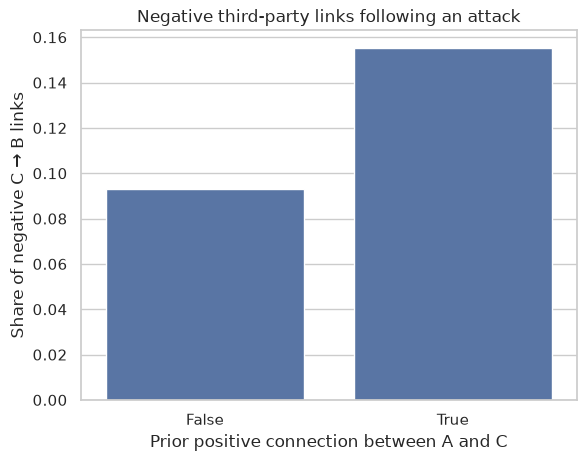

In [ ]:
ax = sns.barplot(x=summary.index, y="negative_share", data=summary)
ax.set_title(
    "Negative third-party links following an attack"
)
ax.set_xlabel("Prior positive connection between A and C")
ax.set_ylabel("Share of negative C → B links")